In [ ]:
import numpy as np
import cv2
import matplotlib.pyplot as plt
from skimage import data

In [ ]:
def mostrar(imagens, titulos, cmap='gray', tamanho=4):
  n = len(imagens)
  plt.figure(figsize=(tamanho*n, tamanho))
  for i in range(n):
    plt.subplot(1, n, i + 1)
    plt.imshow(imagens[i], cmap=cmap)
    plt.title(titulos[i])
    plt.axis('off')
  plt.show()

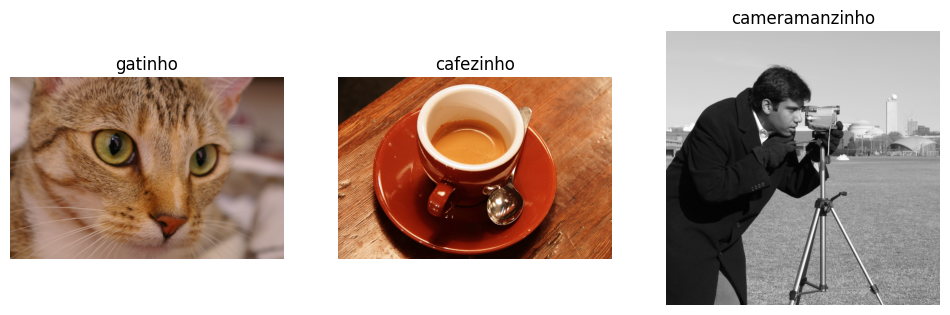

In [ ]:
gato = data.cat()
cafe = data.coffee()
camera = data.camera()

mostrar([gato, cafe, camera], ['gatinho', 'cafezinho', 'cameramanzinho'])

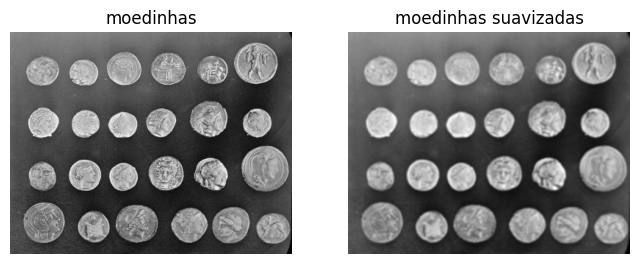

In [ ]:
moedas = data.coins()
moedas_suave = cv2.GaussianBlur(moedas, (5,5), 0)

mostrar([moedas, moedas_suave], ['moedinhas', 'moedinhas suavizadas'])

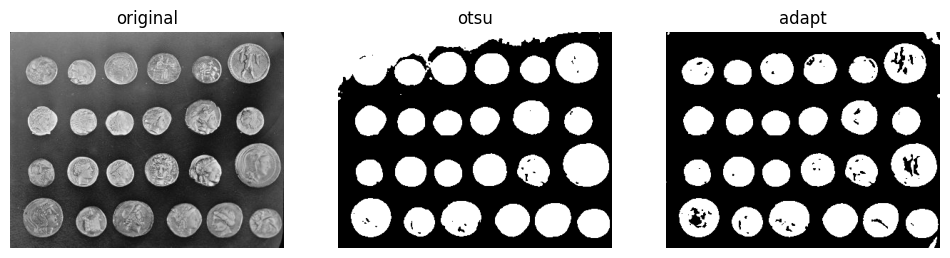

In [ ]:
_, moedas_otsu = cv2.threshold(moedas_suave,
                            0,
                            255,
                            cv2.THRESH_OTSU)

moedas_adapt = cv2.adaptiveThreshold(moedas_suave,
                                     255,
                                     cv2.ADAPTIVE_THRESH_GAUSSIAN_C,
                                     cv2.THRESH_BINARY,
                                     101,
                                     -10)

mostrar([moedas, moedas_otsu, moedas_adapt], ['original', 'otsu', 'adapt'])

In [ ]:
contornos, _ = cv2.findContours(moedas_adapt,
                                cv2.RETR_EXTERNAL,
                                cv2.CHAIN_APPROX_SIMPLE)

contornos = [c for c in contornos if cv2.contourArea(c) > 500]
print('Quantidade de contornos', len(contornos))

Quantidade de contornos 24


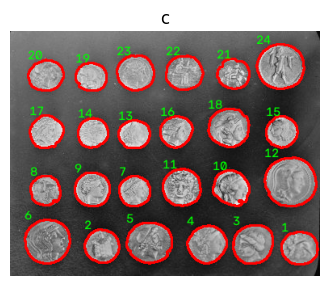

In [ ]:
saida = cv2.cvtColor(moedas, cv2.COLOR_GRAY2RGB)
cv2.drawContours(saida, contornos, -1, (255, 0, 0), 2)

for i, c in enumerate(contornos):
  x, y, w, h = cv2.boundingRect(c)
  cv2.putText(saida, str(i+1), (x, y), cv2.FONT_HERSHEY_SIMPLEX, 0.5, (0, 255, 0))

mostrar([saida], 'contornos')